# C00 Hyperliquid vault strategy

Based on [NB20](20-backtest-c00-vs-v11.ipynb), using the outline of [NB160](../vault-of-vaults/160-backtest-hyperliquid-low-value-treasury-test.ipynb).

C00 ranks vaults with four clipped performance components and allocates to up to six vaults using a regularised 90-day risk estimate and a capacity waterfall. This notebook presents its fixed rules and compares them with `hyper-ai-v11.py`.

Each account starts with USD 150,000. The 2026 backtest runs from **1 January to 4 October 2026**; full history runs from **1 March 2023 to 7 October 2026**, with a partial final archive day. Both retain all preceding indicator warmup.

## Key new insights

All four accounts reproduce NB20's complete equity paths, successful trade sequences and key metrics. This notebook adds a single-strategy reporting layout; it introduces no new strategy configuration.

C00 earns more and has higher Sharpe in both periods. Its full-history drawdown is deeper. The comparison changes ranking, risk estimation and allocation together, so it does not identify which change produced the gain.

## Summary of results

| Period | Strategy | Final equity | CAGR | Sharpe | Maximum drawdown |
| --- | --- | ---: | ---: | ---: | ---: |
| 2026 | C00 | USD 212,376 | 58.59% | 2.474 | -6.36% |
| 2026 | V11 | USD 202,746 | 49.15% | 2.214 | -6.41% |
| Long | C00 | USD 420,882 | 33.13% | 1.651 | -9.94% |
| Long | V11 | USD 277,078 | 18.55% | 1.374 | -7.92% |

## Robustness of results

2026 C00: Realist Capital contributes 35.4% of positive vault profit. The best daily update is 6.46%; excess kurtosis is 11.0.

Long C00: Delta_01 contributes 17.2% of positive vault profit. The best daily update is 15.65%; excess kurtosis is 90.9.

The strongest NAV updates are compared with BTC and ETH over the actual observation intervals and checked against curator exclusions and quarantine. Sparse NAV can bunch returns, and the recorded NAV does not establish the live executable price. These are previously researched, overlapping periods with retrospective universe and guard selection.

Both strategies use the same partial-sale fee correction, entry-tax reset and final-proceeds funding. Charges model 10% of positive redemption profit plus a 0.1% capital allowance; that allowance is an inherited assumption. The v11 comparison runs the local module's rules with these shared research corrections, rather than reproducing recorded live decisions.


## Notebook setup

Load the C00 execution code and report helpers. Charts are saved as separate static images.

In [1]:
from copy import deepcopy
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'c00_template_backtest.py').exists():
    ROOT = ROOT / 'scratchpad/hyperliquid-vov-2nd'
sys.path.insert(0, str(ROOT))
import c00_template_backtest as backtest
from score_matrix_visualisation import compact_output


## Universe definition

Use NB20’s frozen repaired vault archive, metadata, whitelist and guard. All earlier observations remain available for indicator warmup.

In [2]:
with compact_output('Load frozen universe and cached indicator warmup; estimated 2–4 minutes'):
    data, evaluator = backtest.initialise()

display(pd.DataFrame([
    {'Input': 'Strategy', 'Value': str(backtest.common.core.parent.SOURCE)},
    {'Input': 'Reference', 'Value': str(data['nb23_reference'])},
    {'Input': 'Vaults in feature panel', 'Value': len(evaluator.panel.pair_index)},
    {'Input': 'Execution NAV', 'Value': 'Latest actual observation at or before the query'},
    {'Input': 'Indicator warmup', 'Value': 'All available preceding history, including 2025'},
]))

Load frozen universe and cached indicator warmup; estimated 2–4 minutes — complete

,Input,Value
0,Strategy,/Users/moo/code/strategies/strategy/hyper-ai-v...
1,Reference,/Users/moo/code/getting-started/scratchpad/hyp...
2,Vaults in feature panel,514
3,Execution NAV,Latest actual observation at or before the query
4,Indicator warmup,"All available preceding history, including 2025"


## Parameters

C00 retains the source selection and execution limits. Its four-component score, regularised variance and waterfall replace the corresponding v11 rules. The table describes the configuration actually replayed.

In [3]:
Parameters = deepcopy(evaluator.parameters)
assert Parameters.initial_cash == 150000
assert Parameters.max_assets_in_portfolio == Parameters.max_capacity_assets == 6
assert Parameters.inverse_vol_window == 90

parameter_rows = [
    ('Initial capital', 'USD 150,000'),
    ('Decision interval', '2 days'),
    ('C00 ranking score', '0.48 CAGR360 + 0.32 Sortino45 + 0.10 CAGR180 + 0.10 Sortino30'),
    ('CAGR clip', '0–100%, divided by 100%'),
    ('Sortino clip', '0–3, divided by 3'),
    ('Missing score', 'Unscored vaults remain eligible; no component reweighting'),
    ('Risk window / shrinkage', '90 days / 30 actual daily updates'),
    ('Allocation', 'Waterfall ordered by inverse regularised variance'),
    ('Maximum positions / entry rank / exit rank', '6 / 6 / 8'),
    ('Deployment / portfolio cap / pool-TVL cap', '98% / 33% / 33%'),
    ('Minimum vault TVL', 'USD 7,500'),
    ('Momentum gate', '14-day return above −16%'),
    ('Leader-share gate', 'New capital blocked below 5.5% observed leader share'),
    ('Buy / sell threshold', '0.05% / 0.5% of source reference equity, USD 5 floor'),
    ('Tiny-position cleanup', '0.5% source threshold'),
    ('Modelled redemption charges', '10% positive profit + 0.1% gross capital allowance'),
]
display(pd.DataFrame(parameter_rows, columns=['Parameter', 'Value']))

,Parameter,Value
0,Initial capital,"USD 150,000"
1,Decision interval,2 days
2,C00 ranking score,0.48 CAGR360 + 0.32 Sortino45 + 0.10 CAGR180 +...
3,CAGR clip,"0–100%, divided by 100%"
4,Sortino clip,"0–3, divided by 3"
5,Missing score,Unscored vaults remain eligible; no component ...
6,Risk window / shrinkage,90 days / 30 actual daily updates
7,Allocation,Waterfall ordered by inverse regularised variance
8,Maximum positions / entry rank / exit rank,6 / 6 / 8
9,Deployment / portfolio cap / pool-TVL cap,98% / 33% / 33%


## Trading universe

The universe includes supporting reference pairs and Hyperliquid vaults. Supporting pairs supply data; the strategy’s holdings are vaults and cash.

In [4]:
from tradeexecutor.analysis.pair import display_strategy_universe
universe_table = display_strategy_universe(evaluator.universe, compact=True, show_volume=False, show_tax=False)
if hasattr(universe_table, 'data'):
    universe_table = universe_table.data
backtest.show_table(universe_table.reset_index(), limit=12)

id,base,quote,exchange,fee %,price,last_price_at,tvl,pfee,mfee
2697647,WBTC,USDC,uniswap-v3,0.300000,,-,"33,401,277",Unavailable,Unavailable
2697765,WETH,USDC,uniswap-v3,0.050000,,-,"185,394,837",Unavailable,Unavailable
2991521,WETH,USDC,uniswap-v3,0.050000,,-,"902,060",Unavailable,Unavailable
268436013,Storm,USDC,hyperliquid,Unavailable,0.86,7 days 00:00:00,200,10.0%,0.0%
268517186,Hyperliqui,USDC,hyperliquid,Unavailable,0.03,7 days 00:00:00,"3,199",10.0%,0.0%
268521719,AI Crypto,USDC,hyperliquid,Unavailable,0.79,7 days 00:00:00,"40,309",10.0%,0.0%
285026865,Shogun Ris,USDC,hyperliquid,Unavailable,0.83,7 days 00:00:00,"53,953",10.0%,0.0%
285035984,BitRocket,USDC,hyperliquid,Unavailable,1.24,7 days 00:00:00,"18,285",10.0%,0.0%
285065575,Citadel,USDC,hyperliquid,Unavailable,6.85,7 days 00:00:00,"687,114",10.0%,0.0%
285068526,Fund Incep,USDC,hyperliquid,Unavailable,0.97,7 days 00:00:00,"169,062",10.0%,0.0%


## Indicators

Score components use completed prior daily buckets. Risk uses calendar returns carried forward from known NAV after inception; confidence counts actual observations separately.

In [5]:
indicator_rows = [
    ('CAGR360', '360 days', '0.48', 'Unavailable active component makes the score unscored'),
    ('Sortino45', '45 days', '0.32', 'Same missing-score policy'),
    ('CAGR180', '180 days', '0.10', 'Same missing-score policy'),
    ('Sortino30', '30 days', '0.10', 'Same missing-score policy'),
    ('Regularised variance', '90 days', 'Sizing order', 'Partial history and leave-one-out positive peer prior'),
    ('Momentum', '14 days', 'Eligibility', 'Source gate above −16%'),
]
display(pd.DataFrame(indicator_rows, columns=['Indicator', 'Lookback', 'Role / coefficient', 'History handling']))

,Indicator,Lookback,Role / coefficient,History handling
0,CAGR360,360 days,0.48,Unavailable active component makes the score u...
1,Sortino45,45 days,0.32,Same missing-score policy
2,CAGR180,180 days,0.10,Same missing-score policy
3,Sortino30,30 days,0.10,Same missing-score policy
4,Regularised variance,90 days,Sizing order,Partial history and leave-one-out positive pee...
5,Momentum,14 days,Eligibility,Source gate above −16%


## Time range for backtest

Run independent cash-start accounts for each period. End timestamps are exclusive; the full-history archive’s final day is partial.

In [6]:
display(pd.DataFrame([
    {'Period': period, 'Start UTC': start, 'End UTC (exclusive)': end, 'Initial capital (USD)': 150000}
    for period, (start, end) in backtest.PERIODS.items()
]))

,Period,Start UTC,End UTC (exclusive),Initial capital (USD)
0,2026,2026-01-01,2026-10-05,150000
1,Long,2023-03-01,2026-10-08,150000


## Algorithm

Rank eligible vaults by the four-component score, preserving source entry/exit hysteresis and deposit checks. For each selected vault, shrink its 90-day sample variance towards a positive leave-one-out peer median:

\[
\widehat{v}_i=\frac{m_i}{m_i+30}v_i+\frac{30}{m_i+30}v_{\mathrm{peer},i}.
\]

Here \(m_i\) counts actual daily observation updates. Missing own variance uses peer support; missing peer support uses valid positive own variance. If basket risk is unusable, the existing fallback applies. Waterfall fills the highest inverse-risk priority up to its permitted capacity, then passes remaining capital to the next selected vault. Six slots and all source thresholds still apply.

The callback below invokes the exact NB20 C00 implementation. Shared accounting corrects partial-sale charges, clears stale tax on re-entry and limits buys to net synchronous sale proceeds.

In [7]:
def run_c00(period):
    """Replay C00 with the source selector and corrected common accounting."""
    return backtest.common.core.replay(data, evaluator, 'C00', period, active=False)

## Backtest

Run C00 and the v11 control over both periods. Compare all four daily equity paths, successful trade sequences and key metrics against NB20.

In [8]:
with compact_output('Four engine backtests and NB20 replication; estimated 3–10 minutes'):
    results, runs, attribution, absolute_weights = backtest.run_accounts(data, evaluator, run_c00)
with compact_output('Framework reports, curator and market checks; estimated 1–2 minutes'):
    context = backtest.prepare(data, evaluator, results, runs, attribution, absolute_weights)
state = runs[('2026', 'C00')]['result'].state
backtest.table(context, 'parity')

Four engine backtests and NB20 replication; estimated 3–10 minutes — complete

Framework reports, curator and market checks; estimated 1–2 minutes — complete

Period,Strategy,Maximum equity difference (USD),Matching successful trades,All metrics match
2026,C00,USD 0.000000000,473,True
2026,V11,USD 0.000000000,575,True
Long,C00,USD 0.000000000,1044,True
Long,V11,USD 0.000000000,1087,True


## Latest cycle cash and redemption snapshot

**2026-01-01–2026-10-04 UTC.** Final cash and net marked holdings reconcile to account equity. This research execution settles synchronously.

In [9]:
backtest.table(context, 'cash')

Final date,Cash (USD),Invested (USD),Equity (USD),Cash weight,Open vaults
2026-10-04,"USD 146,709.80","USD 65,666.17","USD 212,375.96",69.1%,6


## Capital utilisation through time

**2026-01-01–2026-10-04 UTC.** Actual cash as a fraction of total equity, including capital left over when selected vault capacities bind.

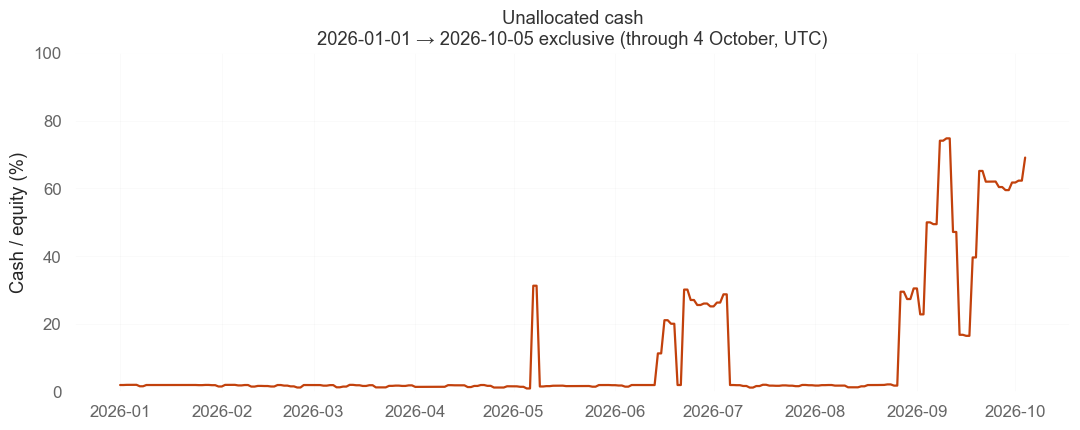

In [10]:
backtest.chart(context, 'cash')

### Capital utilisation summary

**2026-01-01–2026-10-04 UTC.** Cash and funded position counts describe realised deployment. September uses September 2026 observations.

In [11]:
backtest.table(context, 'utilisation')

Mean cash,September cash,Mean vaults held,Maximum vaults held,Largest vault weight
10.2%,49.8%,5.05,6,32.9%


## Survivor selection

**2026-01-01–2026-10-04 UTC.** Count funded vault holdings through time against the six-position limit. This shows actual holdings rather than unfilled candidate slots.

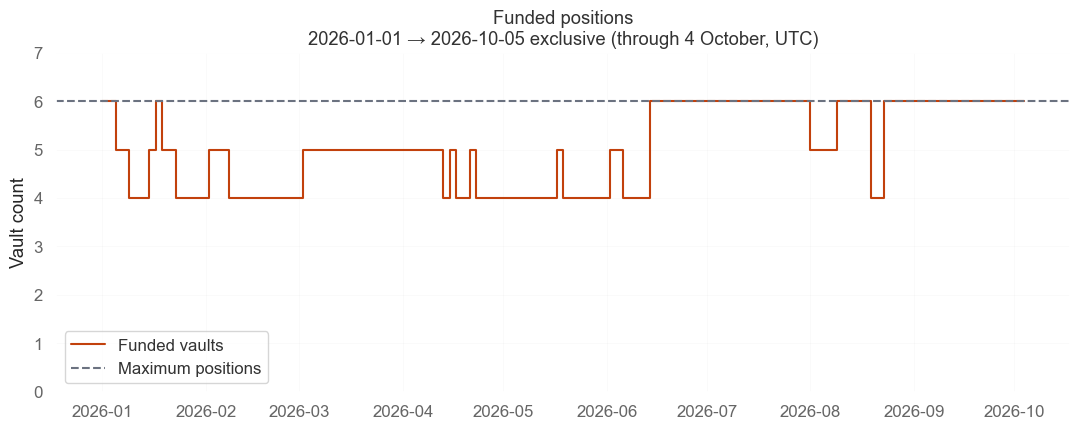

In [12]:
backtest.chart(context, 'selection')

## Performance summary

**2026-01-01–2026-10-04 UTC.** Net account metrics include cash and modelled redemption costs. Daily risk metrics use 365-day annualisation.

In [13]:
backtest.table(context, 'metrics')

,C00
Final equity (USD),"USD 212,375.96"
Net profit (USD),"USD 62,375.96"
Cumulative return,41.58%
CAGR,58.59%
Sharpe,2.474
Sortino,4.532
Calmar,9.215
Maximum drawdown,-6.36%


## Equity curve

**2026-01-01–2026-10-04 UTC.** C00’s net marked account equity, starting with USD 150,000.

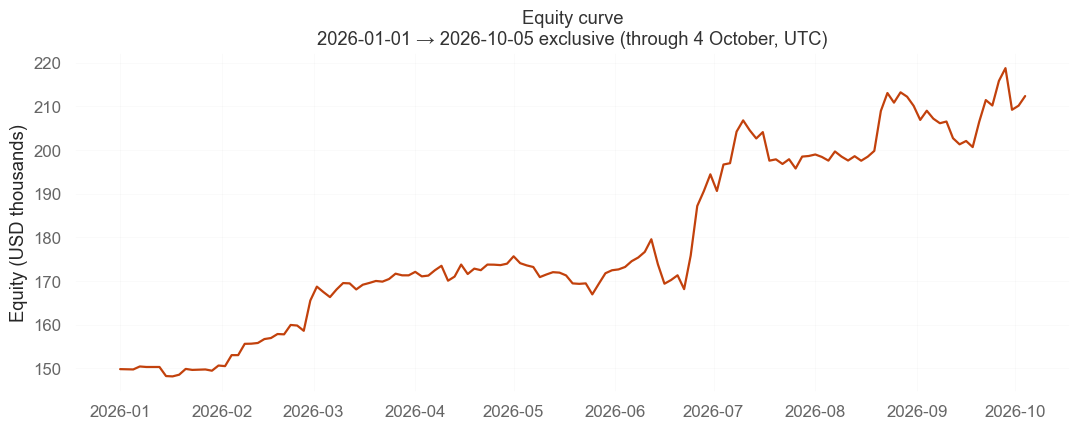

In [14]:
backtest.chart(context, 'equity')

### Equity curve with drawdown

**2026-01-01–2026-10-04 UTC.** Percentage loss from C00’s previous equity peak. Sparse NAV updates can bunch account returns.

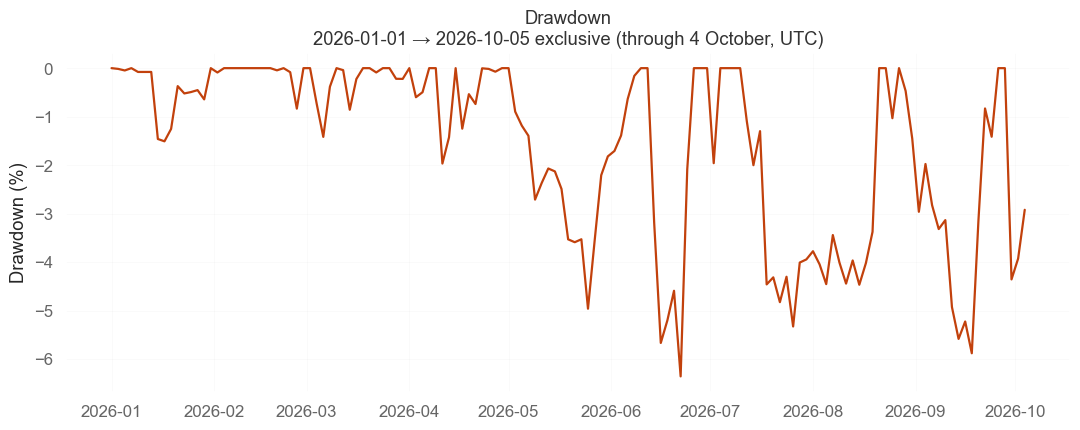

In [15]:
backtest.chart(context, 'drawdown')

## Asset weights

**2026-01-01–2026-10-04 UTC.** Each holding is divided by total equity, including cash. The chart groups the eight largest pooled-average vaults and all remaining vaults.

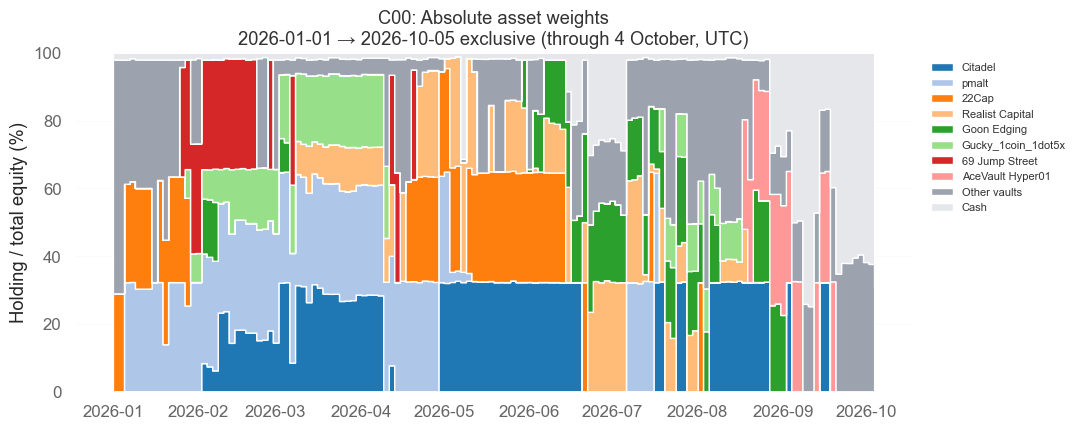

In [16]:
backtest.chart(context, 'absolute')

### Portfolio equity curve breakdown by asset

**2026-01-01–2026-10-04 UTC.** The same asset groups shown in dollars, including cash. Their sum equals portfolio equity.

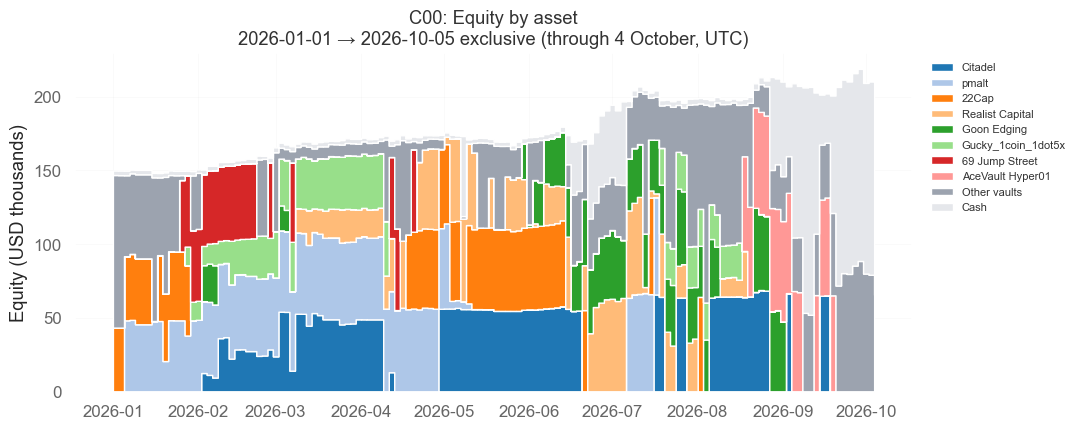

In [17]:
backtest.chart(context, 'asset')

### Portfolio equity curve breakdown by chain

**2026-01-01–2026-10-04 UTC.** C00 holds vaults and cash on Hyperliquid. Supporting market-reference pairs are not portfolio holdings.

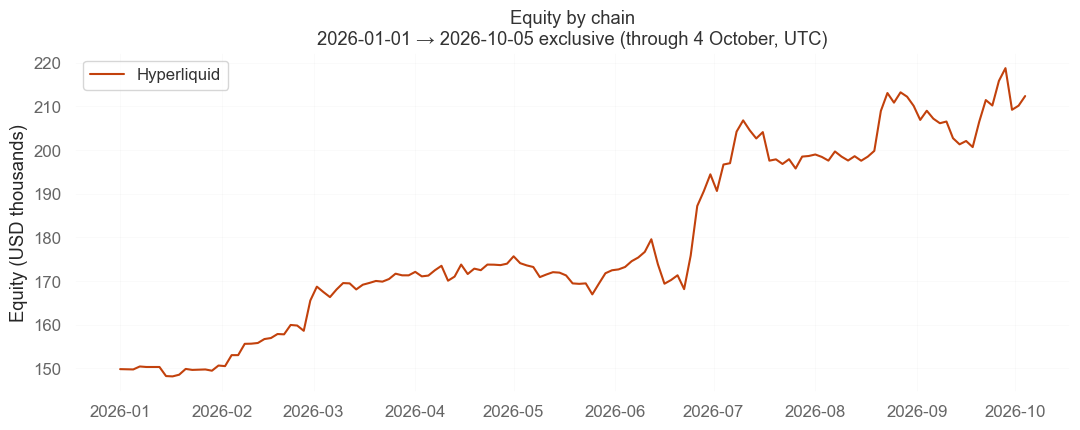

In [18]:
backtest.chart(context, 'chain')

### Weight allocation statistics

**2026-01-01–2026-10-04 UTC.** Framework statistics summarise historical allocation sizes. Reserve cash is included according to the framework’s table convention.

In [19]:
backtest.table(context, 'weights')

Name,At,Pair,Value,Address
Max position (excluding USDC),2026-08-27,AceVault Hyper01,"$69,902.17",
Min position (excluding USDC),2026-05-31,Goon Edging,"$1,690.14",
Mean position (excluding USDC),,,"$31,364.97",
Max position (excluding USDC),2026-09-04,AceVault Hyper01,65.29%,
Min position (excluding USDC),2026-05-31,Goon Edging,1.00%,
Mean position (excluding USDC),,,19.80%,
Max position (including USDC),2026-09-10,USDC,74.74%,
Min position (including USDC),2026-05-07,[ Systemic Strategies ] L/S Grids,0.98%,
Mean position (including USDC),,,16.53%,
---,,,,


## Rolling performance

**2026-01-01–2026-10-04 UTC.** Trailing windows use returns from this account only. The first 89 days have no full-window result.

### Rolling return

**2026-01-01–2026-10-04 UTC.** Compounded account return over the preceding 90 calendar days.

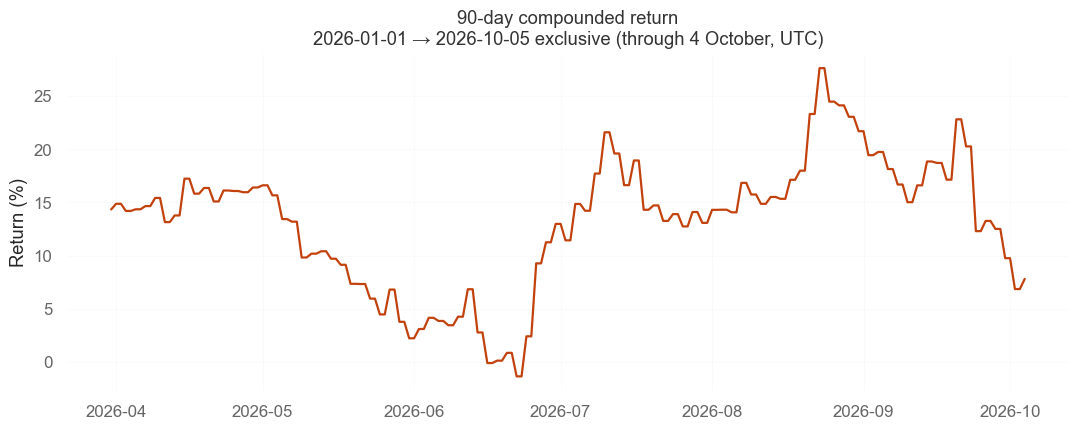

In [20]:
backtest.chart(context, 'rolling_return')

### Rolling Sharpe

**2026-01-01–2026-10-04 UTC.** Mean daily return divided by its sample standard deviation over 90 days, annualised with √365. Zero-risk windows stay undefined.

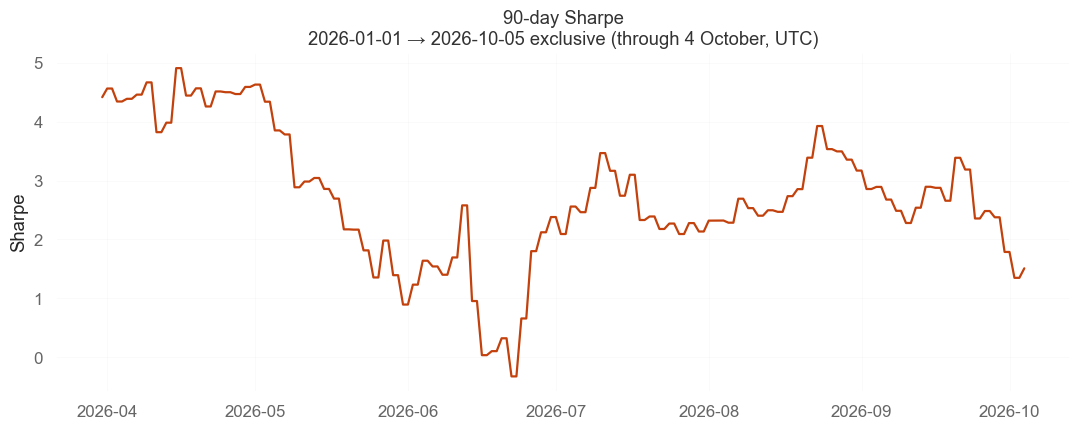

In [21]:
backtest.chart(context, 'rolling_sharpe')

## Monthly returns

**2026-01-01–2026-10-04 UTC.** Compounded monthly account returns. Grey cells have no observations; the first and last months may be partial.

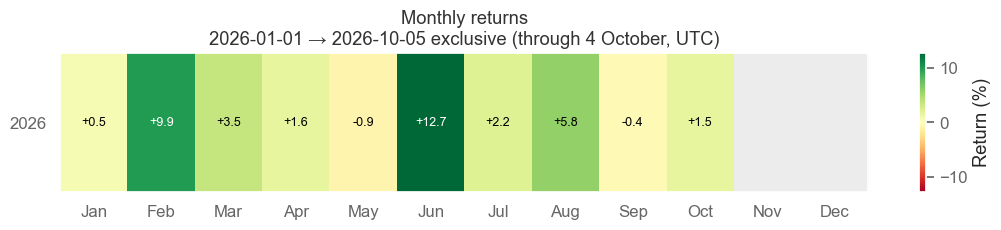

In [22]:
backtest.chart(context, 'monthly')

## Positions at the end

**2026-01-01–2026-10-04 UTC.** Open positions and their net marked value at the final account timestamp.

In [23]:
backtest.table(context, 'positions')

index,Position,Vault,Opened,Value (USD),Weight
2,104,DOEZOE,2026-09-18,"USD 35,035.69",16.5%
3,105,Buyback Spread Engine,2026-09-20,"USD 10,193.52",4.8%
1,100,HYPErQuantum4,2026-09-10,"USD 7,961.95",3.7%
4,106,Sequoia HyperStable Yield Optimizer,2026-09-20,"USD 5,122.87",2.4%
0,96,Gucky_4coin_2dot5x,2026-08-27,"USD 4,345.25",2.0%
5,107,Fadorador,2026-10-04,"USD 3,006.89",1.4%


## Strategy thinking

**2026-01-01–2026-10-04 UTC.** The final source decision log is available below for inspecting permissions, capacity and trade decisions.

In [24]:
backtest.table(context, 'thinking')

<details><summary>Last decision log</summary>

```text
Cycle: #139
Rebalanced: 👍
Open/about to open positions: 7
Trades decided: 4
Pairs meeting inclusion criteria: 236
Pairs meeting TVL inclusion criteria: 239
Candidate signals created: 215
Selected core signals: 6
Selected extension signals: 0
New-entry candidates blocked by deposit admission: 0
Selection score indicator: matrix_score
Weighting method: inverse_variance
Rank exit threshold: 8
Total equity: 212,369.86 USD
Gross reference equity: 212,542.73 USD
Cash: 130,894.91 USD
Fresh deployable capital: 208,122.47 USD
Buy threshold: 106.27 USD
Sell threshold: 1,062.71 USD
Sync cash headroom: 106.27 USD
Pending redemptions: 0.00 USD
Pinned settlement capital: 0.00 USD
Vault positions marked net of redemption fees: 6
Accepted investable equity: 65,642.23 USD
Incumbent top-ups blocked by guard or deposit admission: 10,078.49 USD
Unallocated fresh capital (includes top-ups blocked during sizing): 142,480.24 USD
Rebalance volume: 0.00 USD
Top signal pair: HYPErQuant-USDC
Top signal value: 0.5841940310573839
Top signal weight (normalised): 12.13 %
Signals with flag capped_by_pool_size: 6
Signals with flag capped_by_concentration: 6
Signals with flag individual_trade_size_too_small: 1
Signals with flag close_position_weight_limit: 1
Signals with flag closed: 1
Signals with flag cannot_deposit: 2

```

</details>

## Alpha model diagnostics

**2026-01-01–2026-10-04 UTC.** Source signal diagnostics for the final decision; saved accounts use their final allocation ledger if the transient alpha snapshot is unavailable. Long tables show the first and last rows.

In [25]:
backtest.table(context, 'alpha')

Pair,Signal,Asked size,Accepted size,Value adjust USD,Weights (raw),Weights (norm/cap),Old weight,Flipping,TVL,Pending deposit USD,Pending redemption USD,Parked USD,Waiting deposit USD,Deposit block reason,Deposit block message,Max deposit,Waiting redemption USD,Flags
DOEZOE-USDC,0.003231,68680.413724,35035.685237,0.000000,0.003231,0.533737,0.430018,no flip,121649,-,-,-,5108.372451,vault_deposits_closed,Vault deposits disabled by leader,Unavailable,-,"cannot_deposit, capped_by_pool_size, capped_by_concentration"
Sequoia Hy-USDC,0.005652,68680.413724,5105.025661,-17.839582,0.005652,0.077770,0.062877,no flip,15470,-,-,-,-,-,-,-,-,"individual_trade_size_too_small, capped_by_pool_size, capped_by_concentration"
Fadorador-USDC,0.016464,68680.413724,3009.899517,3009.899517,0.016464,0.045853,0.000000,none -> spot,9121,-,-,-,-,-,-,-,-,"capped_by_pool_size, capped_by_concentration"
Buyback Sp-USDC,0.025211,68680.413724,10193.523402,-1466.541955,0.025211,0.155289,0.143112,no flip,30889,-,-,-,-,-,-,-,-,"capped_by_pool_size, capped_by_concentration"
Gucky_4coi-USDC,0.365248,68680.413724,4336.139515,141.268012,0.365248,0.066057,0.051487,no flip,13140,-,-,-,-,-,-,-,-,"capped_by_pool_size, capped_by_concentration"
HYPErQuant-USDC,0.584194,68680.413724,7961.954845,0.000000,0.584194,0.121293,0.097723,no flip,39188,-,-,-,4970.116050,vault_max_deposit_zero,Historical vault deposit capacity was zero,0.000000,-,"cannot_deposit, capped_by_pool_size, capped_by_concentration"


## Trading pair breakdown

**2026-01-01–2026-10-04 UTC.** Net profit by vault, including closed and open positions, from the reconciled position profit curves. The first and last eight rows are displayed.

In [26]:
backtest.table(context, 'profit')

Vault,Profit (USD)
Realist Capital,"USD +23,668.90"
DOEZOE,"USD +11,137.43"
pmalt,"USD +8,999.82"
[ Systemic Strategies ] L/S Grids,"USD +4,236.73"
Goon Edging,"USD +4,036.61"
22Cap,"USD +3,407.42"
Citadel,"USD +3,265.02"
AceVault Hyper01,"USD +1,674.02"
Satori Quantum HF Vault,USD -119.03
Sequoia HyperStable Yield Optimizer,USD -127.31


## Trading metrics

**2026-01-01–2026-10-04 UTC.** Framework trade summary for this account.

In [27]:
backtest.table(context, 'trades')

,0
Trading period length,276 days 0 hours
Trading start,None
Trading end,None
Return %,41.58%
Annualised return %,54.99%
Cash at start,"$150,000.00"
Value at end,"$212,375.96"
Time in market,0.00%
Time in market volatile,0.00%
Trade volume,"$7,823,572.01"


## Vault performance

**2026-01-01–2026-10-04 UTC.** Vault and position reports use this period’s C00 account.

### Vault statistics

**2026-01-01–2026-10-04 UTC.** Framework vault statistics. Long tables show the first and last six rows.

In [28]:
backtest.table(context, 'vaults')

Metric,Value
Position count,107
Total interest earned,"62,375.96 USD"
Avg interest,54.10%
Min interest,-1128.61%
Max interest,5812.98%
Avg credit position duration,"13 days, 1:34:12.336449"
Total deposit flow in,"3,913,431.11 USD"
Min deposit,100.49 USD
Avg deposit,"13,976.54 USD"
Max deposit,"66,937.49 USD"


### Vault position list

**2026-01-01–2026-10-04 UTC.** Positions ordered by final booked profit, including open marks. The first and last eight rows are displayed.

In [29]:
backtest.table(context, 'position_list')

index,Position id,Vault,Address,Opened,Closed,Final profit (USD)
80,69,Realist Capital,0x77fee2df7bad4f1db93052fa82bf78eaab771a16,2026-06-20 00:00:00,2026-08-01 00:00:00,"USD +32,674.77"
49,8,pmalt,0x4dec0a851849056e259128464ef28ce78afa27f6,2026-01-05 00:00:00,2026-05-11 00:00:00,"USD +12,656.20"
2,104,DOEZOE,0xcae0d1558b70b92ee9fd0acb20cb639c8c28ae69,2026-09-18 00:00:00,Unavailable,"USD +11,815.19"
98,88,AceVault Hyper01,0x9e02aca9865e1859bb7865f6f64801e804a173df,2026-08-17 00:00:00,2026-09-08 00:00:00,"USD +4,798.58"
95,82,Citadel,0xda51323fe9800c8365646ad5c7ade0dd17fdc167,2026-08-05 00:00:00,2026-08-27 00:00:00,"USD +3,941.48"
84,56,Goon Edging,0x2431edfcb662e6ff6deab113cc91878a0b53fb0f,2026-05-29 00:00:00,2026-08-09 00:00:00,"USD +3,471.65"
91,89,[ Systemic Strategies ] L/S Grids,0x07fd993f0fa3a185f7207adccd29f7a87404689d,2026-08-19 00:00:00,2026-08-21 00:00:00,"USD +3,054.56"
27,25,Goon Edging,0x2431edfcb662e6ff6deab113cc91878a0b53fb0f,2026-02-02 00:00:00,2026-02-08 00:00:00,"USD +2,764.11"
96,91,Goon Edging,0x2431edfcb662e6ff6deab113cc91878a0b53fb0f,2026-08-21 00:00:00,2026-09-02 00:00:00,"USD -1,584.20"
76,75,Citadel,0xda51323fe9800c8365646ad5c7ade0dd17fdc167,2026-07-16 00:00:00,2026-07-20 00:00:00,"USD -1,632.52"


## Redemption accounting

**2026-01-01–2026-10-04 UTC.** Executed sell deductions and estimated open liquidation liabilities are reported separately. The 0.1% capital allowance is an inherited assumption.

In [30]:
backtest.table(context, 'fees')

,C00
Paid sell deductions (USD),"USD 13,872.18"
Open performance liability (USD),"USD 1,522.11"
Open capital allowance (USD),USD 67.25
Gross NAV equity (USD),"USD 213,956.07"
Estimated liquidation equity (USD),"USD 212,366.71"
Reported marked equity (USD),"USD 212,375.96"
Open marks vs net estimate (USD),USD 9.25


## Robustness analysis

**2026-01-01–2026-10-04 UTC.** Concentration and extreme-update checks use the actual C00 account. Previously researched history supplies no independent validation.

In [31]:
backtest.table(context, 'robust')

index,Best update,Excess kurtosis,Top positive profit share,Top_vault,Best_date
0,6.46%,11.03,35.4%,Realist Capital,2026-06-26


### Strongest account update

**2026-01-01–2026-10-04 UTC.** The largest account update is attributed to vaults and compared with BTC/ETH over each actual NAV observation interval. Curator flags are shown alongside.

In [32]:
backtest.table(context, 'tail')

index,Update,Vault,Update profit (USD),NAV_return,Interval_days,Excluded,Quarantined,BTCUSDT return,ETHUSDT return
0,2026-06-26,Realist Capital,"USD 6,419",+14.06%,2.04,False,False,-4.69%,-5.96%
1,2026-06-26,Goon Edging,"USD 5,056",+13.86%,2.06,False,False,-4.69%,-5.96%
2,2026-06-26,Octavious Maximus,USD 266,+4.13%,2.05,False,False,-4.69%,-5.96%


## Comparison against hyper-ai-v11.py

The local v11 module runs with the same frozen archive, initial capital, decision timing and research accounting. The comparison changes ranking, risk estimation and allocation together.

### Strategy logic

These fixed rules apply to both periods.

| Rule | V11 | C00 |
| --- | --- | --- |
| Ranking | 0.60 CAGR360 + 0.40 Sortino45 | 0.48 CAGR360 + 0.32 Sortino45 + 0.10 CAGR180 + 0.10 Sortino30 |
| Component clips | CAGR 0–100%; Sortino 0–3, normalised to 0–1 | Same |
| Risk | Source 90-day variance, volatility floor 0.0001 | 90-day variance blended with leave-one-out positive peer median; own weight m/(m+30), m actual updates |
| Allocation | Proportional inverse variance with source capacity adjustment | Waterfall: lowest regularised risk first, filling each permitted capacity |
| Missing score | Composite becomes unscored/zero; eligible vaults can still enter | Same; no available-component reweighting |
| Missing risk | Source missing indicator gives zero raw signal | Partial history and peer prior supported; unusable basket risk falls back to equal raw priorities |
| Maximum positions | 6; no capacity extension | Same |
| Selection | Source rank hysteresis, entry 6 / exit 8, minimum improvement 0 | Same machinery, different score values |
| Limits | 98% deployment, 33% concentration, 33% vault TVL, minimum TVL USD 7,500 | Same |
| Rebalance and gate | Every 2 days; 14-day return must exceed −16% | Same |
| Execution thresholds | Buy 0.05%, sell 0.5% of reference equity, USD 5 floor; cleanup 0.5% | Same |
| Permissions | Source guard, whitelist, deposit/redemption and leader-share policy | Same |



### Key metrics — 2026-01-01–2026-10-04 UTC

Green marks the higher value within each metric. Less negative drawdown is better.

In [33]:
backtest.table(context, 'comparison', '2026')

Arm,C00,V11
Final equity (USD),"USD 212,375.96","USD 202,746.40"
Net profit (USD),"USD 62,375.96","USD 52,746.40"
Cumulative return,41.58%,35.16%
CAGR,58.59%,49.15%
Sharpe,2.474,2.214
Sortino,4.532,3.953
Calmar,9.215,7.673
Maximum drawdown,-6.36%,-6.41%


### Capital usage and trading — 2026-01-01–2026-10-04 UTC

Cash, position counts and turnover show how the rules use capital.

In [34]:
backtest.table(context, 'comparison_cash', '2026')

Arm,C00,V11
Mean cash weight,10.19%,9.09%
September cash,49.75%,42.70%
Mean vaults held,5.047,6.000
Maximum vaults held,6,6
Largest vault weight,32.90%,32.91%
Trades,473,575
Gross trade turnover (USD),"USD 7,823,572.01","USD 7,156,338.45"


### Equity curves — 2026-01-01–2026-10-04 UTC

Both independent accounts use the same dollar scale and initial capital.

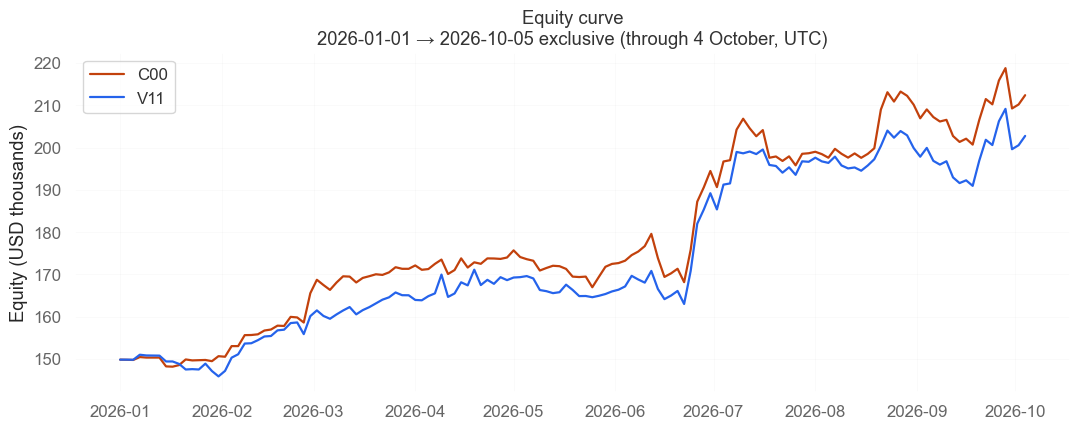

In [35]:
backtest.chart(context, 'equity', '2026', compare=True)

### Drawdown comparison — 2026-01-01–2026-10-04 UTC

Each strategy’s loss from its own previous equity peak.

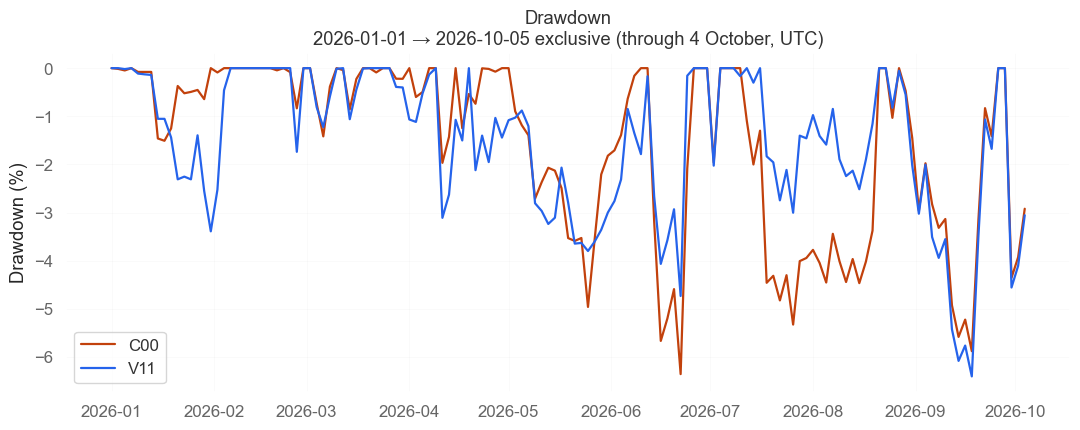

In [36]:
backtest.chart(context, 'drawdown', '2026', compare=True)

### v11 asset weights — 2026-01-01–2026-10-04 UTC

Absolute holding weights, including cash, with the same vault colours and grouping as C00.

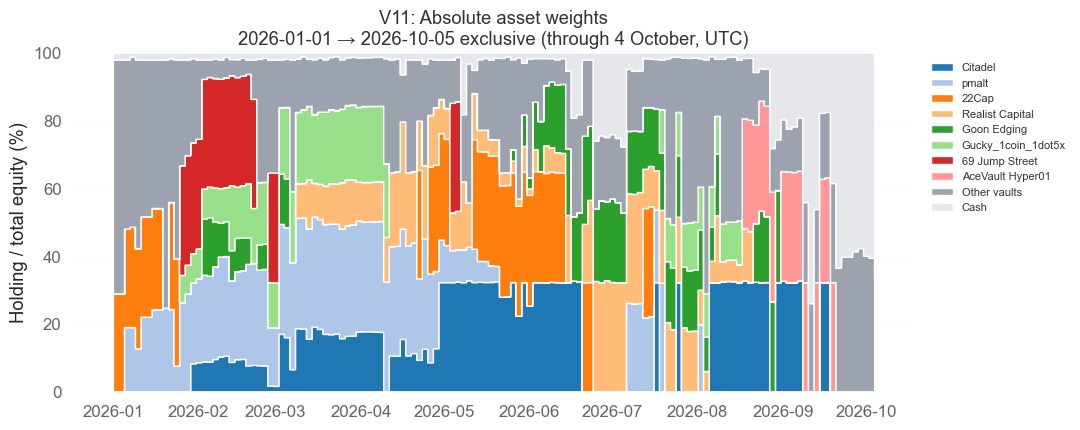

In [37]:
backtest.chart(context, 'absolute', '2026', arm='V11')

### Quarterly returns — 2026-01-01–2026-10-04 UTC

Compounded account returns. An asterisk marks a partial quarter.

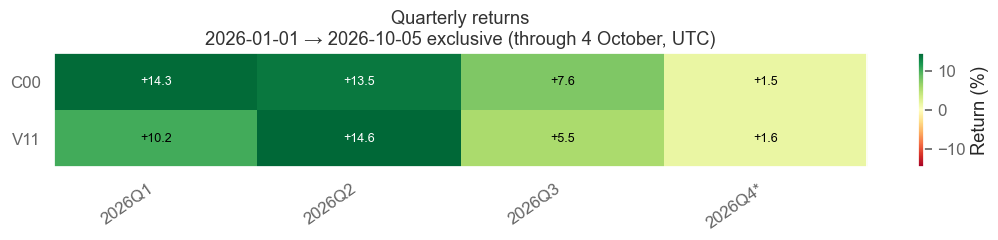

In [38]:
backtest.chart(context, 'quarterly', '2026')

### Vault profit difference — 2026-01-01–2026-10-04 UTC

Ten largest absolute profit differences. These reflect selection, sizing, turnover and compounding jointly.

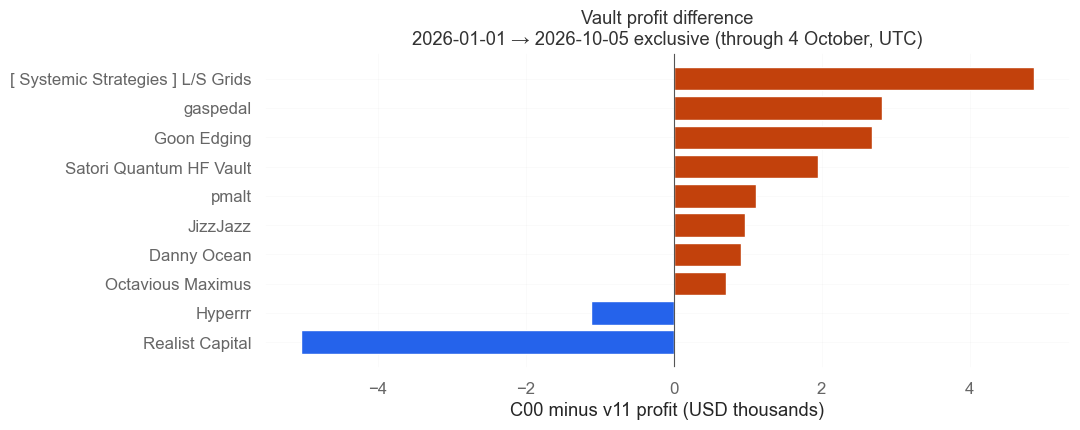

In [39]:
backtest.chart(context, 'contributors', '2026')

### Key metrics — 2023-03-01–2026-10-07 UTC

Green marks the higher value within each metric. Less negative drawdown is better.

In [40]:
backtest.table(context, 'comparison', 'Long')

Arm,C00,V11
Final equity (USD),"USD 420,881.97","USD 277,077.90"
Net profit (USD),"USD 270,881.97","USD 127,077.90"
Cumulative return,180.59%,84.72%
CAGR,33.13%,18.55%
Sharpe,1.651,1.374
Sortino,3.646,2.264
Calmar,3.331,2.344
Maximum drawdown,-9.94%,-7.92%


### Capital usage and trading — 2023-03-01–2026-10-07 UTC

Cash, position counts and turnover show how the rules use capital.

In [41]:
backtest.table(context, 'comparison_cash', 'Long')

Arm,C00,V11
Mean cash weight,39.54%,42.32%
September cash,63.17%,49.46%
Mean vaults held,4.609,4.326
Maximum vaults held,6,6
Largest vault weight,33.35%,33.09%
Trades,"1,044","1,087"
Gross trade turnover (USD),"USD 22,485,064.12","USD 15,159,364.18"


### Equity curves — 2023-03-01–2026-10-07 UTC

Both independent accounts use the same dollar scale and initial capital.

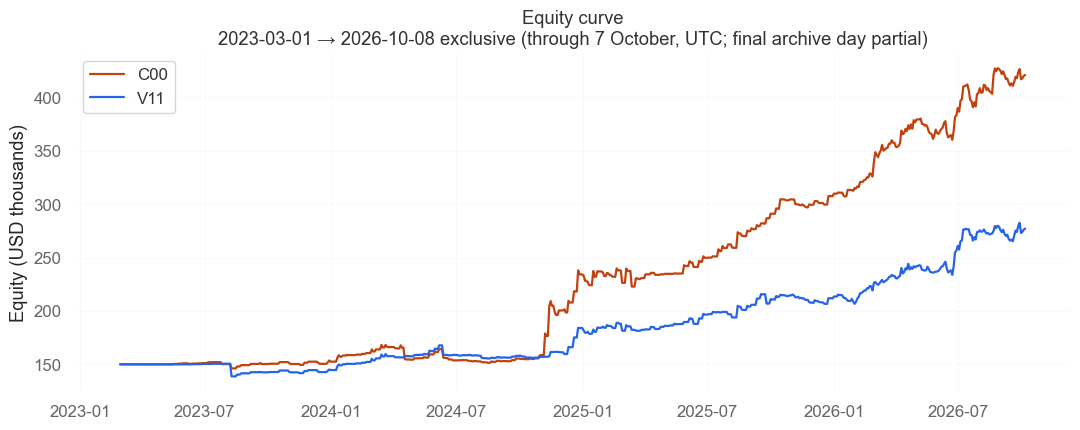

In [42]:
backtest.chart(context, 'equity', 'Long', compare=True)

### Drawdown comparison — 2023-03-01–2026-10-07 UTC

Each strategy’s loss from its own previous equity peak.

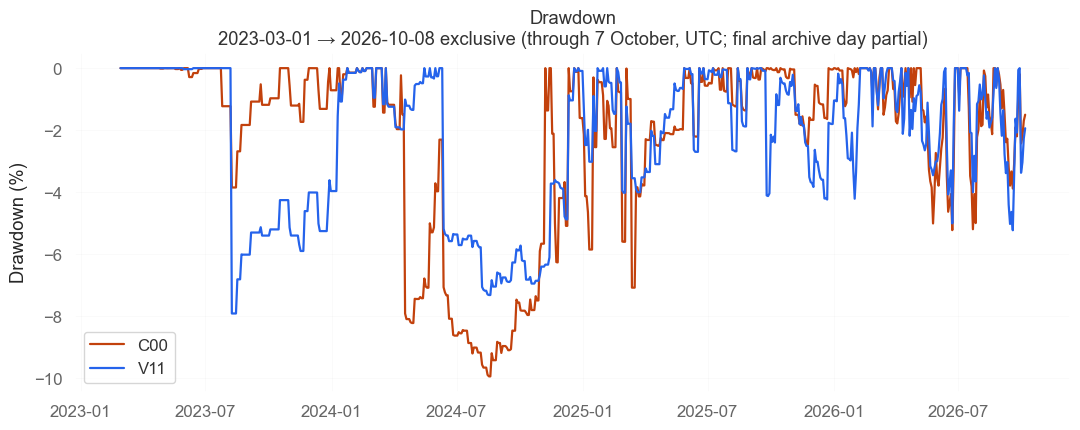

In [43]:
backtest.chart(context, 'drawdown', 'Long', compare=True)

### v11 asset weights — 2023-03-01–2026-10-07 UTC

Absolute holding weights, including cash, with the same vault colours and grouping as C00.

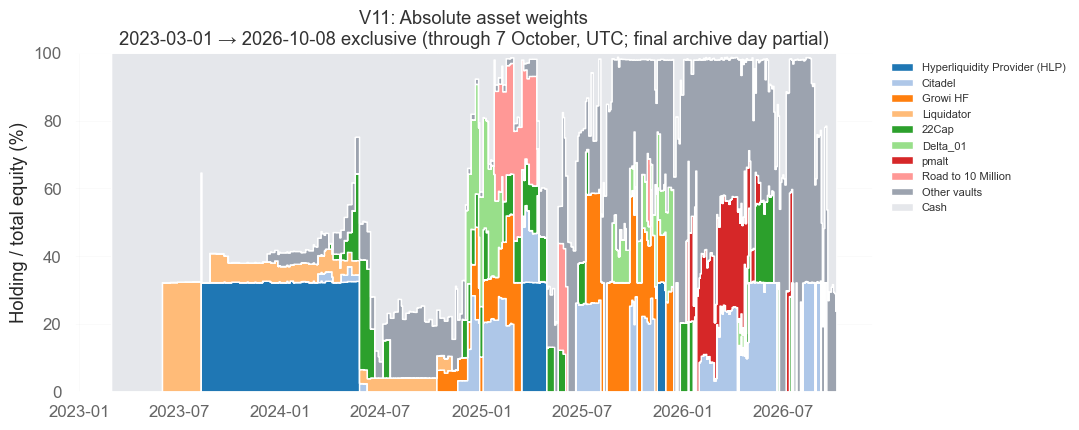

In [44]:
backtest.chart(context, 'absolute', 'Long', arm='V11')

### Quarterly returns — 2023-03-01–2026-10-07 UTC

Compounded account returns. An asterisk marks a partial quarter.

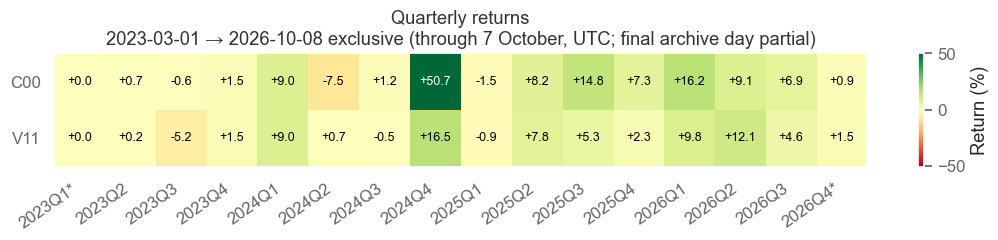

In [45]:
backtest.chart(context, 'quarterly', 'Long')

### Vault profit difference — 2023-03-01–2026-10-07 UTC

Ten largest absolute profit differences. These reflect selection, sizing, turnover and compounding jointly.

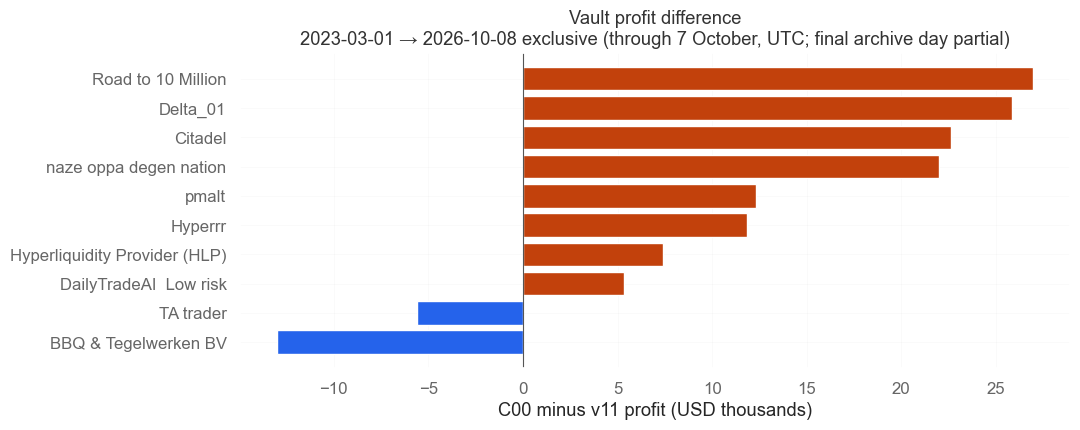

In [46]:
backtest.chart(context, 'contributors', 'Long')

## Full history

**2023-03-01–2026-10-07 UTC.** This is a separate cash-start C00 account. Its 2026 segment includes accumulated wealth and holdings from previous years. The final archive day is partial.

### Performance summary — 2023-03-01–2026-10-07 UTC

Net metrics for the complete C00 account.

In [47]:
backtest.table(context, 'metrics', 'Long')

,C00
Final equity (USD),"USD 420,881.97"
Net profit (USD),"USD 270,881.97"
Cumulative return,180.59%
CAGR,33.13%
Sharpe,1.651
Sortino,3.646
Calmar,3.331
Maximum drawdown,-9.94%


### Equity curve — 2023-03-01–2026-10-07 UTC

C00’s full-history net marked equity.

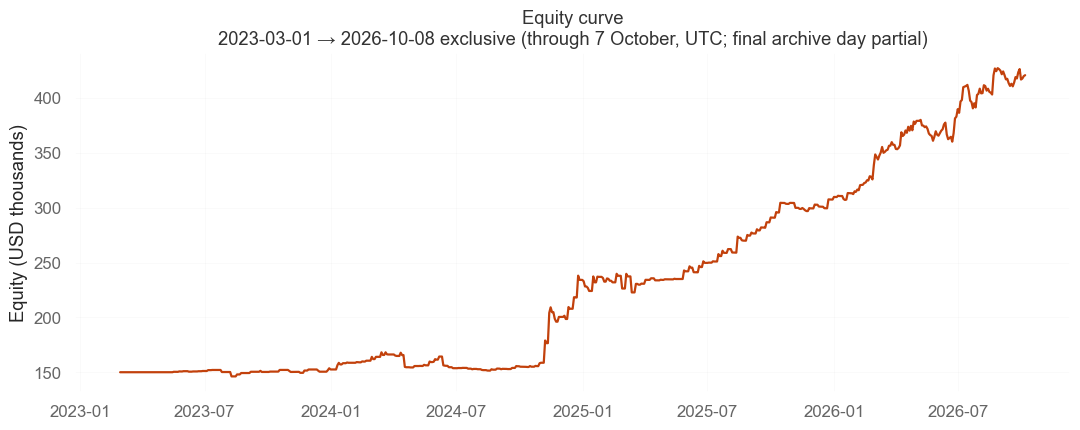

In [48]:
backtest.chart(context, 'equity', 'Long')

### Equity curve with drawdown — 2023-03-01–2026-10-07 UTC

Loss from the account’s running equity peak.

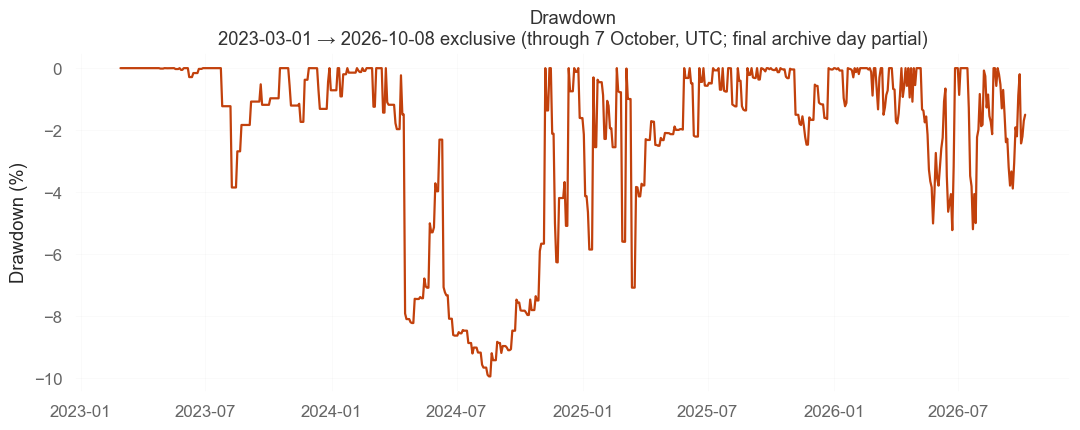

In [49]:
backtest.chart(context, 'drawdown', 'Long')

### Asset weights — 2023-03-01–2026-10-07 UTC

Absolute holding weights including cash, using the same grouping as the full-history v11 comparison.

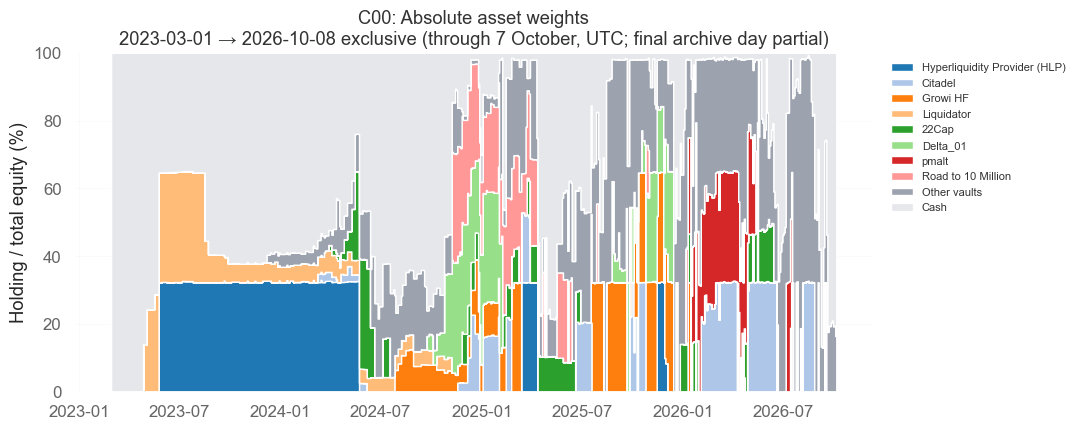

In [50]:
backtest.chart(context, 'absolute', 'Long')

### Monthly returns — 2023-03-01–2026-10-07 UTC

Compounded monthly account returns; grey cells have no observations and boundary months may be partial.

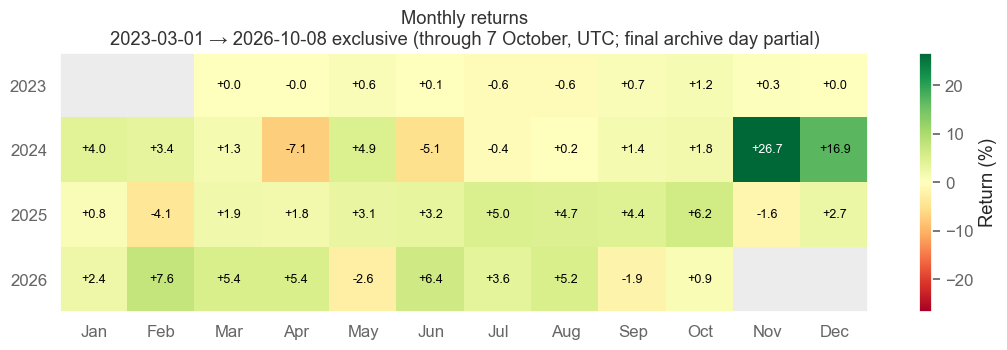

In [51]:
backtest.chart(context, 'monthly', 'Long')

### Capital utilisation summary — 2023-03-01–2026-10-07 UTC

Full-account cash, September 2026 cash and funded positions.

In [52]:
backtest.table(context, 'utilisation', 'Long')

Mean cash,September cash,Mean vaults held,Maximum vaults held,Largest vault weight
39.5%,63.2%,4.61,6,33.3%


### Positions at the end — 2023-03-01–2026-10-07 UTC

Remaining holdings at the final account timestamp.

In [53]:
backtest.table(context, 'positions', 'Long')

index,Position,Vault,Opened,Value (USD),Weight
2,255,DOEZOE,2026-09-18,"USD 34,850.27",8.3%
3,256,Buyback Spread Engine,2026-09-20,"USD 12,144.76",2.9%
1,251,HYPErQuantum4,2026-09-10,"USD 7,961.95",1.9%
4,257,Sequoia HyperStable Yield Optimizer,2026-09-20,"USD 7,211.68",1.7%
0,247,Gucky_4coin_2dot5x,2026-08-27,"USD 4,710.07",1.1%
5,258,Fadorador,2026-10-04,"USD 4,295.77",1.0%


### Robustness analysis — 2023-03-01–2026-10-07 UTC

Profit concentration and extreme daily updates over the complete account.

In [54]:
backtest.table(context, 'robust', 'Long')

index,Best update,Excess kurtosis,Top positive profit share,Top_vault,Best_date
2,15.65%,90.88,17.2%,Delta_01,2024-11-13


### Strongest account update — 2023-03-01–2026-10-07 UTC

Vault NAV and BTC/ETH context over actual observation intervals.

In [55]:
backtest.table(context, 'tail', 'Long')

index,Update,Vault,Update profit (USD),NAV_return,Interval_days,Excluded,Quarantined,BTCUSDT return,ETHUSDT return
6,2024-11-13,Road to 10 Million,"USD 15,536",+30.26%,7.00,False,False,+19.59%,+17.09%
7,2024-11-13,Delta_01,"USD 6,762",+7.26%,6.09,False,False,+19.59%,+17.09%
8,2024-11-13,FFLGN,"USD 4,940",+41.69%,6.07,False,False,+19.59%,+17.09%


## Run details

Record the exact completed generation and source identities for reproducibility.

In [56]:
backtest.finish(context)
display(Markdown('<details><summary>Data and code fingerprints</summary>\n\n```json\n'+__import__('json').dumps(data['manifest'], indent=2, default=str)+'\n```\n\n</details>'))

<!-- nb23-generation: /Users/moo/code/getting-started/scratchpad/hyperliquid-vov-2nd/_artifacts-restored-2026-10-07/23/d405b2df1d52648ef5c2821a9eccbf34d67179628136151f3f55b772d3eb834a -->

Completed four matched accounts and NB20 replication checks.

<details><summary>Data and code fingerprints</summary>

```json
{
  "identity": {
    "version": "nb23-v1",
    "nb20": {
      "version": "nb20-v1",
      "parent": {
        "version": "nb19-v1",
        "inputs": {
          "version": "nb17-v1",
          "nb16_inputs": {
            "version": "nb15-v1",
            "nb14": {
              "version": "nb14-v1",
              "code": {
                "profitable_allocation.py": "a110b6debb07f9961f13e3ff56f9be634bacfd75ec9f98e3e7c8c3f7279d5a88",
                "profitable_allocation_report.py": "4b2587dfec7419fca290f598cca2cea1a64a85c4f2dcd20a5356d5d2cf9c255f",
                "create_profitable_allocation_notebook.py": "b41c7e4b2070eccf79e784f9df61b38d37f3b407b0969875563374a9dbac92ca"
              },
              "nb13_identity": {
                "source_fingerprint": "ea6a622a7706d49ddb818700e6b3d30ccdb412c41bfe0db2c9d1187515c44cdf",
                "extended_universe_fingerprint": "67bffc9ed7d5997250513dd6fba3e00cbc275f91ed65300664a6cc31c49fad1e",
                "feature_panel": "f7e29b5e36a30531933bc2e188dfa30c99e29253b3ccd7071e84f1b0dee35b73",
                "code": {
                  "long_candidate_backtest.py": "1c60331cab792097a436f2e2c0f1d8c6e87f98aabc51a1a633e3c3d98347b1ff",
                  "score_matrix.py": "e3ca6d6bf07f418121dabf91aa6e21d5a9eeaf5cc4bb86120c233e4db089a503",
                  "allocation_followup.py": "eb2513a3d8d0e2e7d6d0cc447c700705d3ec1f01a954d462c898288898d07b87",
                  "allocation_followup_engine.py": "0951f17d4c7ce3af6f3bca2b361d439057535ae12c0433ae006c772aae425048",
                  "portfolio_snapshot_risk.py": "d6a10069cf851d9504eb50fd6698cd05fd3de109d8a91ad76d6ffada4c73b854",
                  "sizing_study_data.py": "fa07af5ed0b936be2fa43ebe410858d28295673554cff0fdda7cedcbded33b1f"
                },
                "shortlist": [
                  {
                    "Candidate": "C01",
                    "Name": "Legacy 45d / 4 inputs / 6m Sortino + 2m CAGR / 6 positions",
                    "Positions": 6.0,
                    "Kind": "score",
                    "Score name": "Legacy 45d / 4 inputs / 6m Sortino + 2m CAGR",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C02",
                    "Name": "Blend 46d / 3 inputs / 6m CAGR / 6 positions",
                    "Positions": 6.0,
                    "Kind": "score",
                    "Score name": "Blend 46d / 3 inputs / 6m CAGR",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C03",
                    "Name": "Legacy 45d / 4 inputs / 6m CAGR + 1m Sortino / 6 positions",
                    "Positions": 6.0,
                    "Kind": "score",
                    "Score name": "Legacy 45d / 4 inputs / 6m CAGR + 1m Sortino",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C04",
                    "Name": "Blend 46d / 7 positions",
                    "Positions": 7.0,
                    "Kind": "score",
                    "Score name": "Blend 46d",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C05",
                    "Name": "Legacy 45d / 4 inputs / 2m CAGR + 6m Sharpe / 6 positions",
                    "Positions": 6.0,
                    "Kind": "score",
                    "Score name": "Legacy 45d / 4 inputs / 2m CAGR + 6m Sharpe",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C06",
                    "Name": "Blend 46d / 4 inputs / 6m Sortino + 2m CAGR / 7 positions",
                    "Positions": 7.0,
                    "Kind": "score",
                    "Score name": "Blend 46d / 4 inputs / 6m Sortino + 2m CAGR",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C07",
                    "Name": "NB12 S18 F:gap_log L90/p2/\u03ba30",
                    "Positions": 6.0,
                    "Kind": "allocation",
                    "Score name": "Legacy 45d / 4 inputs / 6m CAGR + 1m Sortino",
                    "Policy": "S18"
                  },
                  {
                    "Candidate": "C08",
                    "Name": "NB12 X01 F:regular L75/p2/\u03ba30",
                    "Positions": 6.0,
                    "Kind": "allocation",
                    "Score name": "Legacy 45d / 4 inputs / 6m CAGR + 1m Sortino",
                    "Policy": "X01"
                  },
                  {
                    "Candidate": "C09",
                    "Name": "Legacy 45d / 4 inputs / 2m CAGR + 6m Sharpe / 7 positions",
                    "Positions": 7.0,
                    "Kind": "score",
                    "Score name": "Legacy 45d / 4 inputs / 2m CAGR + 6m Sharpe",
                    "Policy": ""
                  },
                  {
                    "Candidate": "C10",
                    "Name": "NB12 S17 F:calendar_log L90/p2/\u03ba30",
                    "Positions": 6.0,
                    "Kind": "allocation",
                    "Score name": "Legacy 45d / 4 inputs / 6m CAGR + 1m Sortino",
                    "Policy": "S17"
                  }
                ],
                "shortlist_data": {
                  "07/2026-results.csv": "860cbacb9fa78a6281276d72a28f9ab08c18610d12368efb8c422d59e6f8ff1f",
                  "12/465e3b8cf13b49e11f635d12c951268318e3b2c39e120f25b89190dd66606be5/engine_summary.parquet": "bb8fabffd0d61bfe4eab10a392873e49cf3fd4a1661439f41082247371909805"
                },
                "downloads": {
                  "vault_prices": {
                    "path": "/Users/moo/code/getting-started/scratchpad/hyperliquid-vov-2nd/_artifacts-restored-2026-10-07/inputs/vault-prices.parquet",
                    "sha256": "30ec7e9dfa7eb236518cf1922a9ba82f4f42cfbfb041c06f5db3273d114aa8f2",
                    "bytes": 289315157
                  },
                  "vault_metadata": {
                    "path": "/Users/moo/code/getting-started/scratchpad/hyperliquid-vov-2nd/_artifacts-restored-2026-10-07/inputs/vault-metadata.json",
                    "sha256": "6c5ec12de41f1c10fc48e54a832eff065d14c77ea19c85fd482c46ea33a5382c",
                    "bytes": 83587673
                  },
                  "permission_sidecar_status": {
                    "http_status": 404,
                    "used": false,
                    "note": "Source strategy uses permission projection; independent endpoint returned 404"
                  }
                },
                "start": "2023-03-01 00:00:00",
                "end": "2026-10-08 00:00:00",
                "control_arms": [
                  "v11",
                  "regular90"
                ]
              },
              "arms": {
                "A": [
                  "Source variance / original allocation",
                  "source",
                  "sequential"
                ],
                "B": [
                  "Source variance / simultaneous allocation",
                  "source",
                  "simultaneous"
                ],
                "C": [
                  "Regularised variance / original allocation",
                  "regular",
                  "sequential"
                ],
                "D": [
                  "Regularised variance / simultaneous allocation",
                  "regular",
                  "simultaneous"
                ],
                "G": [
                  "Regularised downside / original allocation",
                  "downside",
                  "sequential"
                ]
              },
              "periods": {
                "2026": [
                  "2026-01-01 00:00:00",
                  "2026-10-05 00:00:00"
                ],
                "Long": [
                  "2023-03-01 00:00:00",
                  "2026-10-08 00:00:00"
                ]
              },
              "pricing": "as_of_observation",
              "sensitivity": "fresh_quote_within_source_two_day_cycle",
              "initial_cash": 150000
            },
            "source": "/Users/moo/code/strategies/strategy/hyper-ai-v11.py",
            "source_sha256": "5ed8a4c00f1edb14ae9af40ac3d94d3622587445921d1e92ef33f9676761ffbe",
            "code": {
              "allocation_comparison.py": "a7b804e4e4d214d91eee77ee764f914fee998143777065c25809bddaa6db4c76",
              "create_allocation_comparison_notebook.py": "e603ce4edfdf364699177337507baafacef319e4a3777f923a2eba0873430081"
            },
            "arms": [
              "V11",
              "A",
              "C",
              "G"
            ],
            "initial_cash": 150000,
            "periods": {
              "2026": [
                "2026-01-01 00:00:00",
                "2026-10-05 00:00:00"
              ],
              "Long": [
                "2023-03-01 00:00:00",
                "2026-10-08 00:00:00"
              ]
            },
            "pricing": "as_of_observation"
          },
          "arms": {
            "M00": "Exact C-W benchmark",
            "M01": "Admission-aware risk waterfall",
            "M02": "Proportional capped risk",
            "M03": "Score-priority waterfall",
            "M04": "Core + two score-first overflow",
            "M05": "Core + four score-first overflow",
            "M06": "Core + four scored-only overflow",
            "M07": "Capacity-aware incumbent retention",
            "M08": "Greedy score-dollar basket",
            "M09": "Maintained / fee-aware overflow",
            "M10": "One-decision rank-exit confirmation",
            "M11": "Joint six-slot score optimiser",
            "M12": "Legacy capacity extension",
            "M13": "Fixed ten-name core"
          },
          "numerical": {
            "dollar_tolerance": 1e-06,
            "objective_tolerance": 1e-10,
            "mip_rel_gap": 1e-08,
            "time_limit": 30.0
          },
          "code": {
            "capital_allocation.py": "7e4b90c272d628eb3a114aaa0efeff93e18972df0914a9fa818dcc77069a27ab",
            "capital_allocation_methods.py": "9c54723c01be9a0ada347842ddb254717b032703afc02f3ba2c6bcc5aad234b3"
          },
          "source_sha256": "5ed8a4c00f1edb14ae9af40ac3d94d3622587445921d1e92ef33f9676761ffbe"
        },
        "methods": {
          "C00": "Exact corrected C-W",
          "E00": "Flat tickets / hold units",
          "R00": "Risk tickets / hold units",
          "S00": "Score tickets / hold units",
          "RS00": "Score \u00d7 risk / hold units",
          "RS01": "Score \u00d7 risk / resize",
          "NRS00": "Normalised score \u00d7 risk / resize",
          "RS08": "Score \u00d7 risk / eight slots",
          "RS12": "Score \u00d7 risk / twelve slots",
          "GF25": "Score floor 0.25 / hold",
          "CAP10": "Smaller exposure caps / hold"
        },
        "registry": {
          "risk_days": 90,
          "actual_update_shrinkage": 30,
          "score_floor": 0.5,
          "single_gross_cap": 0.05,
          "total_gross_cap": 0.25,
          "ticket_fraction": 0.5,
          "core_slots": 6,
          "entry_rank": 6,
          "exit_rank": 8,
          "missing": true,
          "initial_cash": 150000
        },
        "code": "ad815fcb39ab3bac775434f02bf6fff5429dce2efabd1b08ef804c5a926f76cc"
      },
      "code": "45455be53b9201d10d71e198f3890dd92e2dc72f8b6bbfca5c62eee7b4cb3644",
      "arms": [
        "V11",
        "C00"
      ],
      "accounting": "single partial-sell fee, fresh-entry tax reset, final-proceeds funding",
      "reference": "/Users/moo/code/getting-started/scratchpad/hyperliquid-vov-2nd/_artifacts-restored-2026-10-07/19/4cf096b0443683cc5ebffa060b3756829c64a636160ae9c3b4d6b1a5f81ab6b4"
    },
    "reference": "/Users/moo/code/getting-started/scratchpad/hyperliquid-vov-2nd/_artifacts-restored-2026-10-07/20/43eea0e427a4571a73b4ac32c50bb29ecbdac66e8542dd4573a6401182641911",
    "template": "scratchpad/vault-of-vaults/160-backtest-hyperliquid-low-value-treasury-test.ipynb",
    "code": {
      "c00_template_backtest.py": "e3db214565d0b8a523a3eed28b1eae72fa417a1edfcf525b071cba2bc69e01f2",
      "create_c00_template_notebook.py": "f57b4233893b2d45aa198c965b765182ee3d7395d35726a48430242d017b7e3e"
    }
  },
  "framework": {
    "getting-started": "0be3392775ffd2567a617153a3c8d42fb0e57476",
    "trade-executor": "2db909b32d854d342f159074b2b92948f32b69d6",
    "trading-strategy": "unavailable",
    "web3-ethereum-defi": "unavailable"
  },
  "periods": {
    "2026": [
      "2026-01-01 00:00:00",
      "2026-10-05 00:00:00"
    ],
    "Long": [
      "2023-03-01 00:00:00",
      "2026-10-08 00:00:00"
    ]
  },
  "limitations": [
    "Researched overlapping histories, retrospective universe/guard",
    "NAV observation timestamp assumed available; executable NAV unverified",
    "Inherited 10% profit and 0.1% capital fee allowances",
    "Same-state core intentions are protected; future wealth and core membership can change"
  ],
  "fingerprint": "d405b2df1d52648ef5c2821a9eccbf34d67179628136151f3f55b772d3eb834a"
}
```

</details>